# Forecasting intraday index returns: Shang [[46]](../docs/references.md#ref-shang-2017a), replicated

Shang [[46]](../docs/references.md#ref-shang-2017a) forecasts the S&P 500's intraday path a day ahead by treating each trading day as
one observation of a function. The transform is his equation (1): a day's five-minute prices
become the **cumulative intraday return** curve

$$ X_t(s) \;=\; 100\,\bigl[\log P_t(s) - \log P_t(0)\bigr], \qquad s \in [0, 1], $$

which starts at exactly zero and carries the shape of the session rather than its level. The
sequence $X_1, \dots, X_n$ is then a functional time series, and the method is the one of
Hyndman & Shang [[30]](../docs/references.md#ref-hyndman-shang-2009): decompose once,

$$ X_t(s) \;=\; \mu(s) + \sum_{k=1}^{M} \psi_{t,k}\,\phi_k(s) + e_t(s), $$

forecast each score series $\{\psi_{t,k}\}_t$ on its own, and reassemble
$\hat X_{n+h}(s) = \hat\mu(s) + \sum_k \hat\psi_{n+h,k}\,\hat\phi_k(s)$. One dependent sequence
of functions becomes $M$ dependent sequences of scalars, all of the temporal modelling happens
in $\mathbb{R}^M$, and prediction intervals come from a bootstrap that resamples both of the
error sources the reconstruction has.

**What this notebook can and cannot claim.** Shang's own numbers are out of reach in any
language: the data is Thomson Reuters Tick History for a specific window of 2015, and without
that series no implementation lands on his point forecasts. What is replicable is the *method*
and its *claims*: that a couple of components carry ninety per cent of the variation, that the
reconstruction residuals show no pattern, and that the two score forecasters differ little. That
is what is checked here, on 125 sessions of five-minute S&P 500 prices from the first half of
2017, committed as `data/spx_1m_2017H1.csv`. Two divergences are structural rather than
incidental. R's `auto.arima` searches the order grid stepwise and `ftsa.forecast` searches all
of it, so on a near-tie the two can select different orders. And the paper pairs this forecaster
with *dynamic updating*, revising the forecast of the rest of a day once its first hours are
observed, which is developed at greater length in the companion paper on particulate matter
(Shang [[47]](../docs/references.md#ref-shang-2017b)). That half is `notebooks/shang_updating.ipynb`; what is replicated here is the
one-day-ahead forecast it starts from.

There is one addition. The paper's accuracy tables compare its forecasters with each other, and
this notebook also compares them with the flat forecast that predicts every session by the
average of the sessions before it. An accuracy table with no floor in it cannot say whether a
method has found anything, and that turns out to be the interesting part.

`ftsa/README.md` documents the implementation and carries the references in full, including both
of the 2017 papers; `notebooks/overnight_jumps.ipynb` is where the curves used here come from,
and `notebooks/jump_equation.ipynb` is the model for the quantity this transform deletes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from fts_research.core import style
from fts_research.fdaSP import intraday as itd
from fts_research.ftsa import evaluation as ev
from fts_research.ftsa import forecast as fc

style.use(plt)

X, grid, dates = ev.replication_curves()
n_sessions, tau = X.shape

# One colour per method throughout: the two forecasters take hues, the flat forecast is a
# control rather than a competitor and takes the recessive grey.
COLOUR = {"arima": style.CATEGORICAL[0], "far": style.CATEGORICAL[1], "mean": style.CONTROL}
LABEL = {"arima": "univariate ARIMA", "far": "FAR(1) on the scores",
         "mean": "flat forecast (benchmark)"}

print(f"S&P 500, {dates[0]} to {dates[-1]}")
print(f"  {n_sessions} sessions x tau = {tau} five-minute marks, the opening anchor dropped")
print(f"  CIDR ranges from {X.min():+.3f}% to {X.max():+.3f}%, "
      f"pointwise sd at the close {X[:, -1].std():.3f}%")

S&P 500, 2017-01-03 to 2017-06-30
  125 sessions x tau = 78 five-minute marks, the opening anchor dropped
  CIDR ranges from -1.551% to +1.023%, pointwise sd at the close 0.344%


## 1. The curves, and what the transform throws away

Every session is anchored at its own opening price, so every curve begins at zero and the
sample spreads out from there. That spread is the first thing to look at, because it is not a
modelling assumption: if intraday log prices were a diffusion, the pointwise standard deviation
would grow like $\sqrt{s}$, and how far it departs from that says how much structure there is
beyond the random walk before any model is fitted.

Anchoring is also what makes the overnight move invisible. $X_t(0) = 0$ by construction, so the
gap between last night's close and this morning's open is not in the data this method sees,
although it is a large fraction of the daily return and is what
`notebooks/overnight_jumps.ipynb` is about. That is a property of the transform, not of the
forecaster, and it is worth stating before anything is forecast at all.

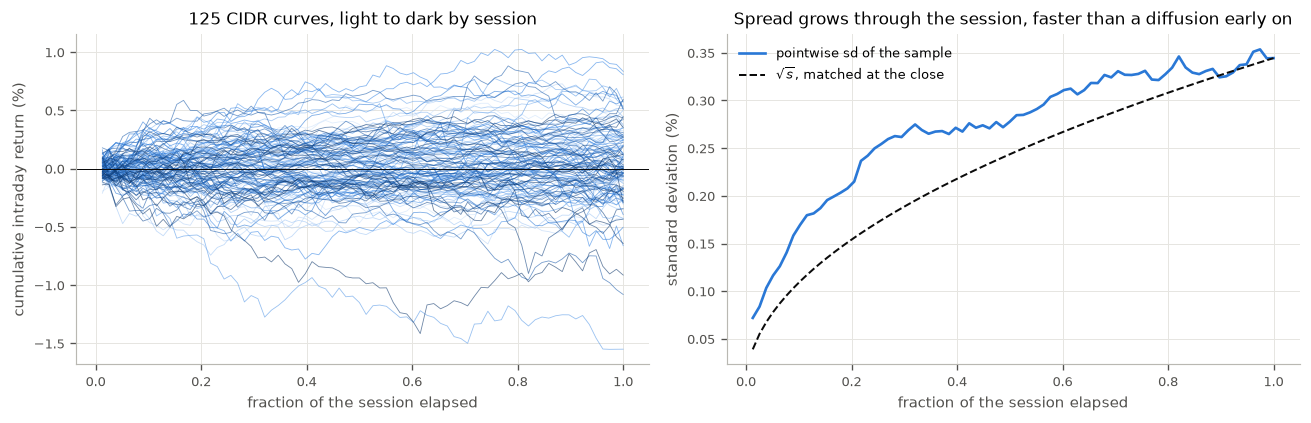

pointwise sd: 0.0719% at the first retained mark, 0.3445% at the close
sample sd over the matched sqrt(s) curve: 0.990 to 1.537
largest gap 0.0808%, at s = 0.269
the anchor the transform imposes is zero on all 125 sessions: True


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

shade = style.ordinal(n_sessions, lightest=0)
for i, row in enumerate(X):
    ax[0].plot(grid, row, color=shade[i], lw=0.5, alpha=0.6)
ax[0].axhline(0, color=style.INK, lw=0.6)
ax[0].set_xlabel("fraction of the session elapsed")
ax[0].set_ylabel("cumulative intraday return (%)")
ax[0].set_title(f"{n_sessions} CIDR curves, light to dark by session")

sd = X.std(axis=0)
diffusion = sd[-1] * np.sqrt(grid)
ax[1].plot(grid, sd, color=style.CATEGORICAL[0], lw=1.6, label="pointwise sd of the sample")
ax[1].plot(grid, diffusion, color=style.INK, ls="--", lw=1.2,
           label=r"$\sqrt{s}$, matched at the close")
ax[1].set_xlabel("fraction of the session elapsed")
ax[1].set_ylabel("standard deviation (%)")
ax[1].set_title("Spread grows through the session, faster than a diffusion early on")
ax[1].legend()
plt.tight_layout()
plt.show()

ratio = (sd / diffusion)[1:]
worst = int(np.argmax(np.abs(sd - diffusion)))
print(f"pointwise sd: {sd[0]:.4f}% at the first retained mark, {sd[-1]:.4f}% at the close")
print(f"sample sd over the matched sqrt(s) curve: {ratio.min():.3f} to {ratio.max():.3f}")
print(f"largest gap {np.abs(sd - diffusion).max():.4f}%, at s = {grid[worst]:.3f}")

# The dropped column, checked on the curves before the anchor was removed.
raw, _raw_grid, _raw_dates = itd.session_curves(itd.load_spx_2017(), n_points=79, min_bars=1)
print(f"the anchor the transform imposes is zero on all {len(raw)} sessions: "
      f"{bool(np.all(raw[:, 0] == 0))}")

## 2. The decomposition

`ftsa.forecast.decompose` is `far.far_est.fpca` truncated by Shang's rule: keep the fewest
components explaining at least 90% of total variation. The components are orthonormal in $L^2$
under `core.quadrature`'s trapezium weights, which is the same inner product every other
estimate in this repository is taken under, so the scores here are exactly the scores
`far_est.far1_fit` regresses, and the two forecasters compared below differ in what they do with
the scores and in nothing else.

components retained at the 90% rule: M = 2
  phi_1:  85.14% of variance,  85.14% cumulative
  phi_2:   7.24% of variance,  92.38% cumulative
reconstruction residual rms: 0.0778%


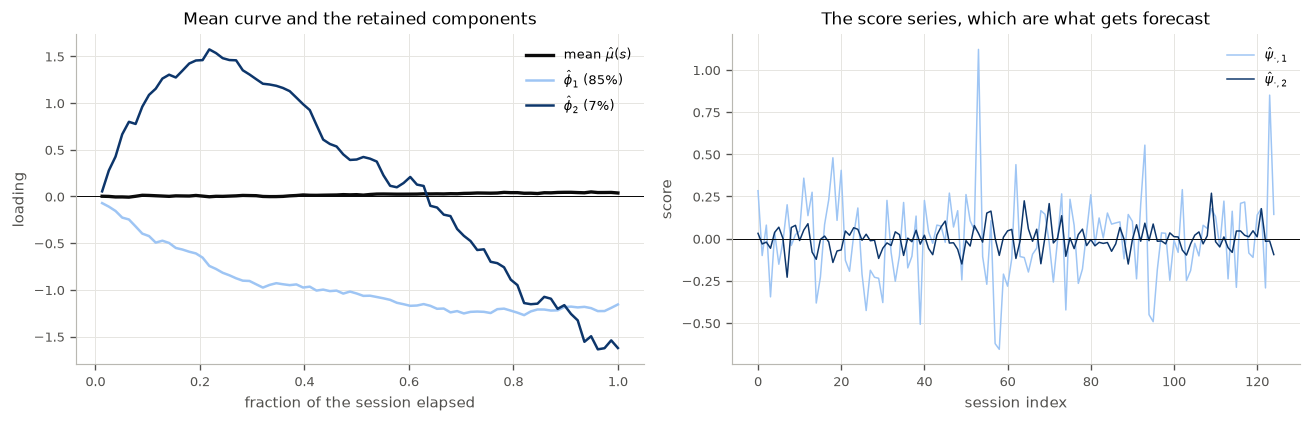

In [3]:
dec = fc.decompose(X, grid)
M = dec["n_components"]

print(f"components retained at the 90% rule: M = {M}")
for k in range(M):
    print(f"  phi_{k + 1}: {100 * dec['tau'][k] / dec['total']:6.2f}% of variance, "
          f"{100 * dec['explained'][k]:6.2f}% cumulative")
print(f"reconstruction residual rms: {np.sqrt(np.mean(dec['resid_curves'] ** 2)):.4f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(grid, dec["mean"], color=style.INK, lw=2, label=r"mean $\hat\mu(s)$")
for k, colour in zip(range(M), style.ordinal(M, lightest=2)):
    ax[0].plot(grid, dec["phi"][k], color=colour, lw=1.5,
               label=fr"$\hat\phi_{{{k + 1}}}$ ({100 * dec['tau'][k] / dec['total']:.0f}%)")
ax[0].axhline(0, color=style.INK, lw=0.6)
ax[0].set_xlabel("fraction of the session elapsed")
ax[0].set_ylabel("loading")
ax[0].set_title("Mean curve and the retained components")
ax[0].legend()

for k, colour in zip(range(M), style.ordinal(M, lightest=2)):
    ax[1].plot(np.arange(n_sessions), dec["scores"][:, k], color=colour, lw=0.9,
               label=fr"$\hat\psi_{{\cdot,{k + 1}}}$")
ax[1].axhline(0, color=style.INK, lw=0.6)
ax[1].set_xlabel("session index")
ax[1].set_ylabel("score")
ax[1].set_title("The score series, which are what gets forecast")
ax[1].legend()
plt.tight_layout()
plt.show()

The shapes are the ones the paper describes and they are worth naming, because everything the
forecaster can say about tomorrow is a statement about these two numbers. The first component is
monotone in $s$ and is essentially the size of the day's total move: a session that ends up has
a positive first score, one that ends down a negative one. The second changes sign about the
middle of the session, so it separates a day that rose and then fell from one that did the
reverse. Nothing beyond those two reaches the 90% threshold.

The residual image plot is the paper's own adequacy check: with enough components retained, what
is left should show no pattern in either direction, i.e. no band of sessions the model
systematically misses and no stretch of the trading day it systematically misses. It is worth
being precise about which pattern that rules out, because one of the two is present.

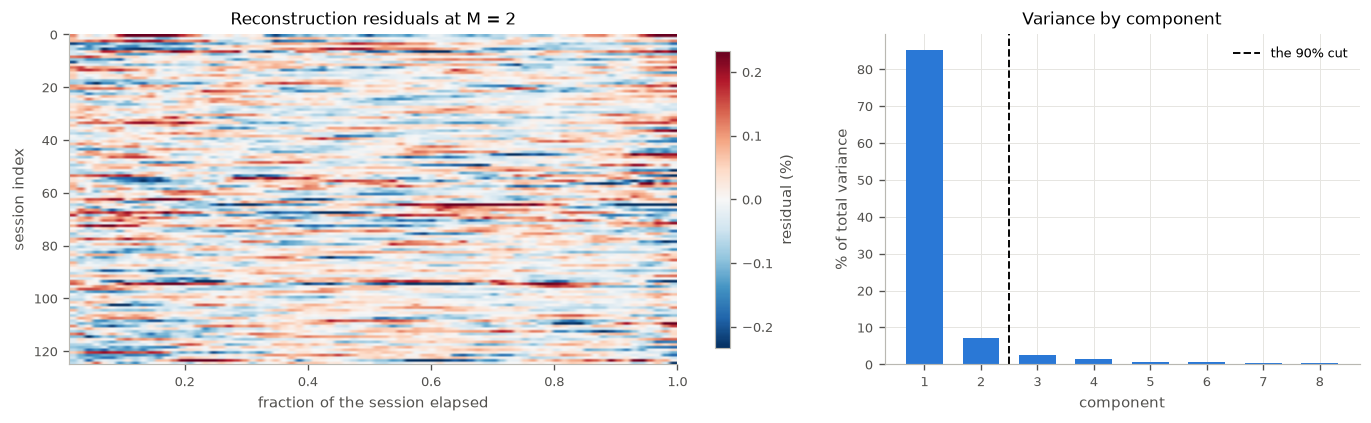

mean |residual| by session: 0.0191% to 0.1600%
mean |residual| by intraday point: 0.0457% to 0.0906%
lag-1 autocorrelation of the session-mean residual: +0.2078


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6), width_ratios=[1.6, 1])

resid = dec["resid_curves"]
lim = np.percentile(np.abs(resid), 99)
im = ax[0].imshow(resid, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim,
                  extent=[grid[0], grid[-1], n_sessions, 0])
ax[0].grid(False)
ax[0].set_xlabel("fraction of the session elapsed")
ax[0].set_ylabel("session index")
ax[0].set_title(f"Reconstruction residuals at M = {M}")
plt.colorbar(im, ax=ax[0], shrink=0.9, label="residual (%)")

full = fc.decompose(X, grid, n_components=8, max_components=8)
share = 100 * full["tau"] / full["total"]
ax[1].bar(np.arange(1, 9), share, color=style.SEQUENTIAL_STEPS[7], width=0.65)
ax[1].axvline(M + 0.5, color=style.INK, ls="--", lw=1.2, label="the 90% cut")
ax[1].set_axisbelow(True)
ax[1].set_xlabel("component")
ax[1].set_ylabel("% of total variance")
ax[1].set_title("Variance by component")
ax[1].legend()
plt.tight_layout()
plt.show()

rows = np.abs(resid).mean(axis=1)
cols = np.abs(resid).mean(axis=0)
print(f"mean |residual| by session: {rows.min():.4f}% to {rows.max():.4f}%")
print(f"mean |residual| by intraday point: {cols.min():.4f}% to {cols.max():.4f}%")
print(f"lag-1 autocorrelation of the session-mean residual: "
      f"{np.corrcoef(rows[:-1], rows[1:])[0, 1]:+.4f}")

No structure survives in the *level* of the residuals: they are symmetric about zero and no
stretch of the session is biased. Their *magnitude* is another matter. The mean absolute
residual varies eightfold across sessions, and it is autocorrelated from one session to the next
at $+0.2078$; quiet days are followed by quiet days.

That is not a failure of the decomposition, and adding components would not remove it. It is
volatility clustering, which lives in the conditional variance, while the entire method (mean
function, components, score forecasts) models the conditional mean. Hold on to it: it is what
section 7 turns out to be about.

## 3. Forecasting the scores, and the bootstrap bands

Two routes, and they are the two Shang compares.

**Univariate ARIMA.** The scores are uncorrelated across $k$ by construction, so a separate
model per series is the principled default; the order is chosen by corrected AIC over the
$(p,d,q)$ grid up to order three, which is the criterion `auto.arima` uses.

**A vector autoregression on the score vector.** At order one this is not merely *like* `far.far_est`'s operator; it *is* it. `ftsa.forecast.forecast_scores` calls `far_est.score_operator`, so the comparison below is Shang's forecaster against this repository's FAR(1), fitted on identical components. That is what makes it worth running: the multivariate route can use cross-lag dependence between scores that $M$ univariate models cannot see, and whether there is any is an empirical question.

The bands are the paper's nonparametric bootstrap (§5.1), which resamples both error sources
a reconstructed curve has: the score forecast errors, drawn from each component's own in-sample
one-step residuals, and the residual functions the truncation at $M$ left behind. Neither is
given a distribution, which is the point of doing it this way on returns.

ARIMA orders chosen, one per component: [(1, 0, 1), (0, 0, 2)]


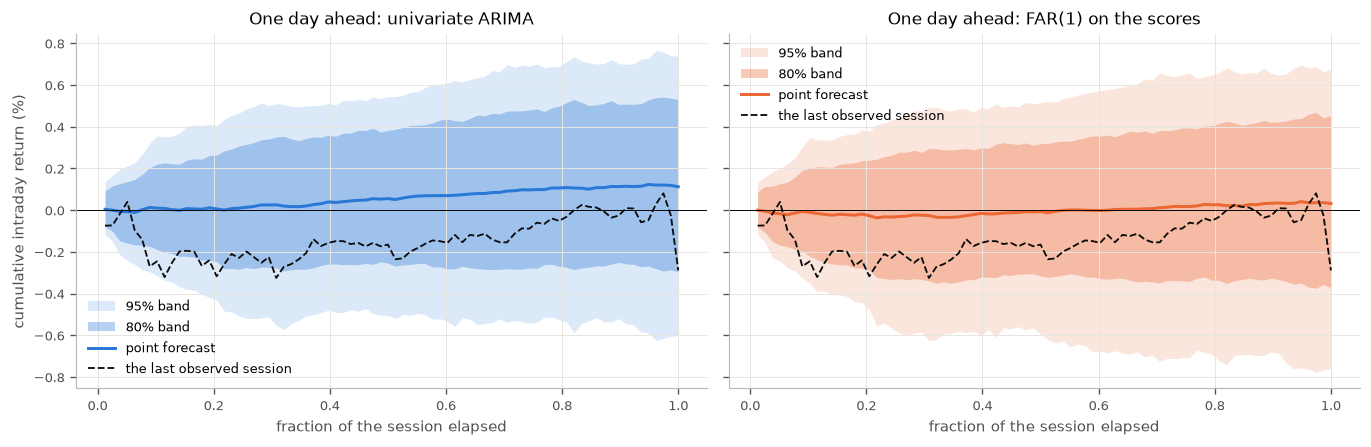

univariate ARIMA           point forecast at the close +0.1126%, 80% band width 0.6356%
FAR(1) on the scores       point forecast at the close +0.0322%, 80% band width 0.6280%


In [5]:
fits = {m: fc.forecast_curves(X, grid, h=1, method=m, n_boot=2000, rng=0)
        for m in ("arima", "far")}
print(f"ARIMA orders chosen, one per component: {fits['arima']['orders']}")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for axis, method in zip(ax, ("arima", "far")):
    band = fits[method]["forecast"]
    lo95, hi95 = band["bands"][0.95]
    lo80, hi80 = band["bands"][0.80]
    axis.fill_between(grid, lo95[0], hi95[0], color=COLOUR[method], alpha=0.16, lw=0,
                      label="95% band")
    axis.fill_between(grid, lo80[0], hi80[0], color=COLOUR[method], alpha=0.34, lw=0,
                      label="80% band")
    axis.plot(grid, band["center"][0], color=COLOUR[method], lw=1.8, label="point forecast")
    axis.plot(grid, X[-1], color=style.INK, lw=1.1, ls="--", label="the last observed session")
    axis.axhline(0, color=style.INK, lw=0.6)
    axis.set_xlabel("fraction of the session elapsed")
    axis.set_title(f"One day ahead: {LABEL[method]}")
    axis.legend()
ax[0].set_ylabel("cumulative intraday return (%)")
plt.tight_layout()
plt.show()

for method in ("arima", "far"):
    band = fits[method]["forecast"]
    lo, hi = band["bands"][0.80]
    print(f"{LABEL[method]:<26} point forecast at the close "
          f"{band['center'][0, -1]:+.4f}%, 80% band width {np.mean(hi - lo):.4f}%")

## 4. Rolling-origin accuracy

The protocol behind the paper's tables, and the only one that settles anything: expanding
window, one step ahead, the model re-estimated at every split, so nothing is fitted on a curve
it is later scored against. The first 75 sessions train and the remaining 50 are the holdout.

Three measures, all Shang's: mean absolute and mean squared forecast error, and Gneiting &
Raftery's interval score, which is the one that scores a *band*. It pays for the width and is
charged in proportion to how far outside the realised curve falls, so a band cannot buy a better
score by being either wide or narrow. Empirical coverage is reported alongside, since the two
answer different questions.

The whole evaluation takes minutes, most of them spent searching ARIMA orders afresh at every
split, so `ftsa.evaluation.cached_rolling` reads the committed forecasts from
`artifacts/cache/`. What is cached is the forecasts rather than the scores, so every number
below is recomputed here from what was actually predicted.

In [6]:
frame = ev.cached_rolling()
table = ev.summarise(frame)


def as_matrix(part, column):
    """(sessions, grid) matrix of one column of a cached forecast frame, in date order."""
    return part.pivot(index="session", columns="t", values=column).sort_index().to_numpy()


actual = as_matrix(frame[frame["method"] == "arima"], "actual")
point = {m: as_matrix(part, "point") for m, part in frame.groupby("method")}
lower = {m: as_matrix(part, "lower") for m, part in frame.groupby("method")}
upper = {m: as_matrix(part, "upper") for m, part in frame.groupby("method")}

print(table.rename(index=LABEL).round(5).to_string())
print(f"\nheldout sessions: {actual.shape[0]}, each of {actual.shape[1]} intraday points")

                              mafe     msfe   iscore  coverage  n_splits
method                                                                  
univariate ARIMA           0.21391  0.07448  0.91763   0.79051        50
FAR(1) on the scores       0.19268  0.06820  0.91321   0.83128        50
flat forecast (benchmark)  0.19083  0.06655  0.89817   0.82641        50

heldout sessions: 50, each of 78 intraday points


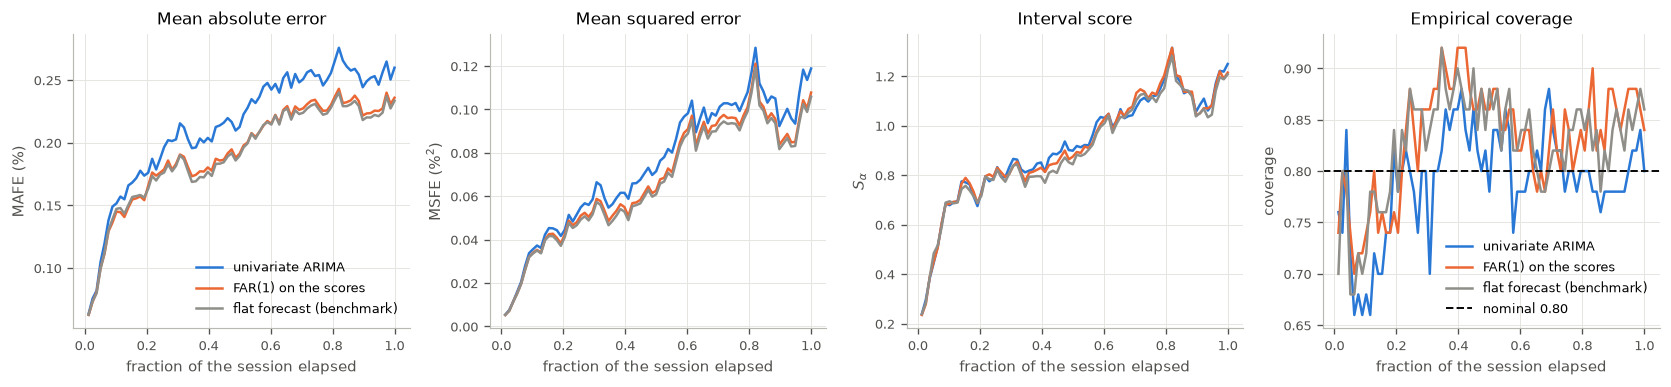

In [7]:
alpha = ev.CONFIG["alpha"]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.3))
for method in ("arima", "far", "mean"):
    error = actual - point[method]
    score = ev.interval_score(lower[method], upper[method], actual, alpha)
    covered = (actual >= lower[method]) & (actual <= upper[method])
    for axis, series in zip(ax, (np.mean(np.abs(error), axis=0), np.mean(error ** 2, axis=0),
                                 score.mean(axis=0), covered.mean(axis=0))):
        axis.plot(grid, series, color=COLOUR[method], lw=1.5, label=LABEL[method])

ax[3].axhline(1 - alpha, color=style.INK, ls="--", lw=1.2, label="nominal 0.80")
for axis, title, ylabel in zip(
        ax,
        ["Mean absolute error", "Mean squared error", "Interval score", "Empirical coverage"],
        ["MAFE (%)", "MSFE (%$^2$)", r"$S_\alpha$", "coverage"]):
    axis.set_xlabel("fraction of the session elapsed")
    axis.set_ylabel(ylabel)
    axis.set_title(title)
ax[0].legend()
ax[3].legend()
plt.tight_layout()
plt.show()

Two things are visible before any test. Every measure grows through the session, which is the
diffusion shape of section 1 arriving again: the further into the day, the more there is to get
wrong, and no forecaster changes that. And the three curves sit almost on top of one another,
with the flat forecast at or below both of the fitted ones for most of the session.

## 5. The floor

The paper's tables compare its forecasters with each other. The question they do not ask is
whether either beats predicting nothing, and there are two versions of nothing worth asking
about: the **flat forecast**, which predicts each session by the mean of the sessions before
it, and the **zero curve**, which predicts no move at all. On CIDR curves the second is a
serious benchmark rather than a straw man, since the sample mean function is itself a small
estimated drift.

The comparison is paired, every method forecasting the same 50 sessions, so the right test is on
the per-session differences in squared error, not on the two grand means separately.

In [8]:
point["zero"] = np.zeros_like(actual)
LABEL["zero"] = "zero curve (no move at all)"
COLOUR["zero"] = style.INK


def session_mse(prediction):
    """Mean squared forecast error of each held-out session, so methods can be paired."""
    return np.mean((actual - prediction) ** 2, axis=1)


base = session_mse(point["zero"]).mean()
print(f"{'method':<28}{'MAFE':>9}{'MSFE':>10}{'R2 vs the zero curve':>23}")
for method in ("arima", "far", "mean", "zero"):
    mse = session_mse(point[method]).mean()
    mafe = np.mean(np.abs(actual - point[method]))
    print(f"{LABEL[method]:<28}{mafe:>9.5f}{mse:>10.5f}{1 - mse / base:>+23.4f}")

print("\npaired over the 50 held-out sessions, on squared error:")
for a, b in (("far", "arima"), ("arima", "mean"), ("far", "mean"), ("mean", "zero")):
    d = session_mse(point[a]) - session_mse(point[b])
    t = d.mean() / (d.std(ddof=1) / np.sqrt(d.size))
    print(f"  {a:>5} - {b:<5} mean difference {d.mean():+.5f}, "
          f"t = {t:+.3f}, p = {2 * stats.t.sf(abs(t), d.size - 1):.4f}")

method                           MAFE      MSFE   R2 vs the zero curve
univariate ARIMA              0.21391   0.07448                -0.1468
FAR(1) on the scores          0.19268   0.06820                -0.0502
flat forecast (benchmark)     0.19083   0.06655                -0.0247
zero curve (no move at all)   0.18770   0.06495                +0.0000

paired over the 50 held-out sessions, on squared error:
    far - arima mean difference -0.00628, t = -1.217, p = 0.2293
  arima - mean  mean difference +0.00793, t = +1.633, p = 0.1089
    far - mean  mean difference +0.00165, t = +1.332, p = 0.1890
   mean - zero  mean difference +0.00160, t = +0.766, p = 0.4472


arima      interval score 0.91763, mean width 0.6391%, coverage 0.7905
far        interval score 0.91321, mean width 0.6363%, coverage 0.8313
empirical  interval score 0.89817, mean width 0.6096%, coverage 0.8264


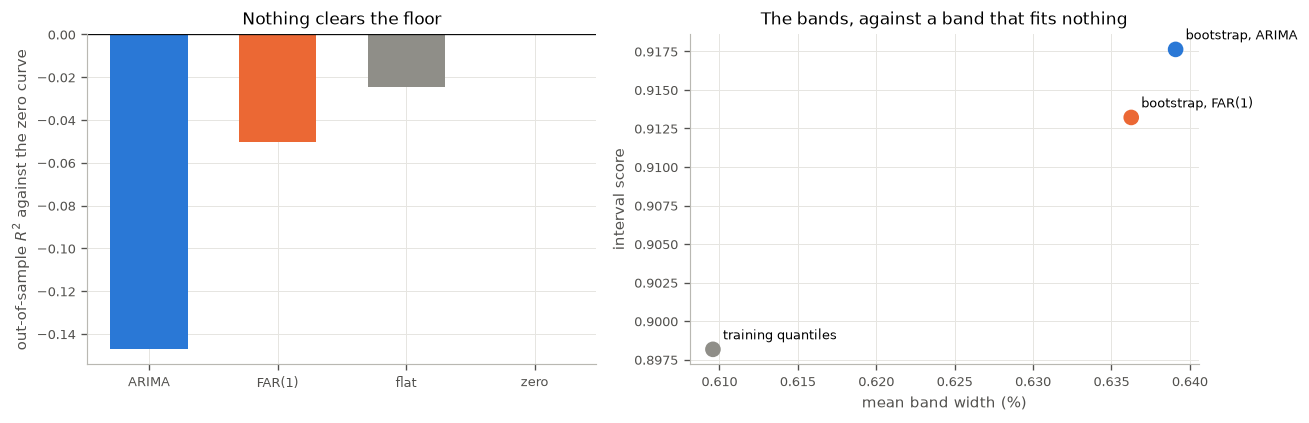

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

order = ("arima", "far", "mean", "zero")
ax[0].bar(np.arange(4), [1 - session_mse(point[m]).mean() / base for m in order],
          color=[COLOUR[m] for m in order], width=0.6)
ax[0].axhline(0, color=style.INK, lw=0.8)
ax[0].set_axisbelow(True)
ax[0].set_xticks(np.arange(4))
ax[0].set_xticklabels(["ARIMA", "FAR(1)", "flat", "zero"])
ax[0].set_ylabel(r"out-of-sample $R^2$ against the zero curve")
ax[0].set_title("Nothing clears the floor")

# The bands are the other half of the paper's output, and have their own floor: the empirical
# quantiles of the training sessions, which fit nothing at all.
emp_lo = np.vstack([np.quantile(X[:s], alpha / 2, axis=0)
                    for s in range(len(X) - actual.shape[0], len(X))])
emp_hi = np.vstack([np.quantile(X[:s], 1 - alpha / 2, axis=0)
                    for s in range(len(X) - actual.shape[0], len(X))])
widths, scores = [], []
for method, lo, hi in (("arima", lower["arima"], upper["arima"]),
                       ("far", lower["far"], upper["far"]),
                       ("empirical", emp_lo, emp_hi)):
    widths.append(np.mean(hi - lo))
    scores.append(ev.interval_score(lo, hi, actual, alpha).mean())
    cover = np.mean((actual >= lo) & (actual <= hi))
    print(f"{method:<10} interval score {scores[-1]:.5f}, mean width {widths[-1]:.4f}%, "
          f"coverage {cover:.4f}")

ax[1].scatter(widths, scores, s=70,
              color=[COLOUR["arima"], COLOUR["far"], style.CONTROL], zorder=3)
for label, w, sc in zip(["bootstrap, ARIMA", "bootstrap, FAR(1)", "training quantiles"],
                        widths, scores):
    ax[1].annotate(label, (w, sc), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax[1].set_xlabel("mean band width (%)")
ax[1].set_ylabel("interval score")
ax[1].set_title("The bands, against a band that fits nothing")
plt.tight_layout()
plt.show()

## 6. Nine instruments: the method, or the window?

Everything above is one index over one half-year. `ftsa.evaluation.cached_panel` runs the same
evaluation over the nine instruments of this repository's five-minute snapshot panel, on the
same transform and the same protocol, with roughly sixty sessions each and so twenty-four
held-out sessions apiece. Each on its own settles much less than the 2017 window does; it is the
agreement across the nine that carries the weight.

method    arima      far     mean  ARIMA beats flat  FAR(1) beats flat
ticker                                                                
AAPL    0.69768  0.70537  0.67762             False              False
AMZN    1.60957  1.47848  1.42287             False              False
MSFT    1.19011  1.11051  1.08099             False              False
NVDA    2.04023  1.90324  2.20055              True               True
QQQ     0.65557  0.44338  0.51113             False               True
SPY     0.24454  0.14734  0.16638             False               True
TSLA    2.96608  2.81769  2.87156             False               True
^FTSE   0.10941  0.10038  0.09085             False              False
^GSPC   0.26471  0.14769  0.16741             False               True



of 9 instruments, the flat forecast is beaten by ARIMA 1 times and by the FAR(1) 5 times
the FAR(1) route is more accurate than the univariate route on 8 of 9, sign test p = 0.0391

skill against the flat forecast, as out-of-sample R2:
  univariate ARIMA           -0.5812 to +0.0729, median -0.1312
  FAR(1) on the scores       -0.1050 to +0.1351, median +0.0188


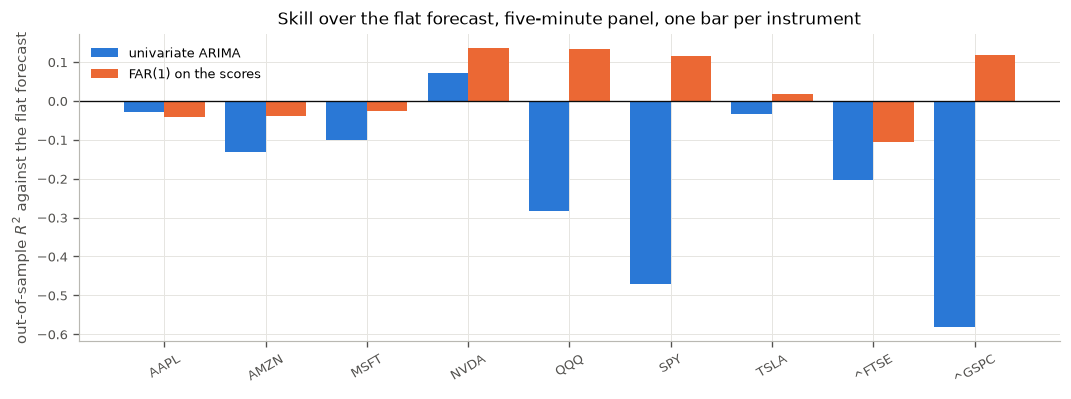

In [10]:
panel = ev.cached_panel()
per_ticker = ev.summarise(panel, by=["ticker", "method"])["msfe"].unstack("method")
per_ticker["ARIMA beats flat"] = per_ticker["arima"] < per_ticker["mean"]
per_ticker["FAR(1) beats flat"] = per_ticker["far"] < per_ticker["mean"]
print(per_ticker.round(5).to_string())

wins = per_ticker[["ARIMA beats flat", "FAR(1) beats flat"]].sum()
print(f"\nof {len(per_ticker)} instruments, the flat forecast is beaten by "
      f"ARIMA {wins.iloc[0]} times and by the FAR(1) {wins.iloc[1]} times")

better = int((per_ticker["far"] < per_ticker["arima"]).sum())
print(f"the FAR(1) route is more accurate than the univariate route on {better} of "
      f"{len(per_ticker)}, sign test p = "
      f"{stats.binomtest(better, len(per_ticker), 0.5).pvalue:.4f}")
print("\nskill against the flat forecast, as out-of-sample R2:")
for method in ("arima", "far"):
    skill = 1 - per_ticker[method] / per_ticker["mean"]
    print(f"  {LABEL[method]:<26} {skill.min():+.4f} to {skill.max():+.4f}, "
          f"median {skill.median():+.4f}")

fig, ax = plt.subplots(figsize=(9, 3.4))
pos = np.arange(len(per_ticker))
for offset, method in ((-0.2, "arima"), (0.2, "far")):
    skill = 1 - per_ticker[method] / per_ticker["mean"]
    ax.bar(pos + offset, skill, width=0.4, color=COLOUR[method], label=LABEL[method])
ax.axhline(0, color=style.INK, lw=0.8)
ax.set_axisbelow(True)
ax.set_xticks(pos)
ax.set_xticklabels(per_ticker.index, rotation=30)
ax.set_ylabel(r"out-of-sample $R^2$ against the flat forecast")
ax.set_title("Skill over the flat forecast, five-minute panel, one bar per instrument")
ax.legend()
plt.tight_layout()
plt.show()

## 7. What the replication says

**The descriptive claims reproduce.** Two components clear ninety per cent of the variation, they have the shapes the paper describes, a level factor and a mid-session sign change; the reconstruction residuals show no pattern in either direction, and the automatic order search picks low-order ARMA models for both score series. Every step of the pipeline behaves as described, on data the paper never saw.

**Neither forecaster clears the floor on the 2017 window.** Both are beaten there by the flat forecast and by the zero curve, and none of the gaps is significant: paired over 50 sessions the fitted forecasters are not separated from the flat forecast, and the flat forecast is not separated from predicting no move at all. The honest reading is not that the method is worse than doing nothing; it is that on that window there is nothing in the conditional mean of the curve sequence for any of them to find, so all four land in the same place and the ordering between them is noise.

**The two routes do not differ little.** This is where the replication parts company with the paper, which reports the univariate and multivariate routes as close. Across the nine instruments the FAR(1) route is the more accurate on eight, which a sign test puts at $p = 0.0391$, and it is ahead on the 2017 window too. The margins are not small either: against the flat forecast the univariate route runs from $-0.5812$ to $+0.0729$ in out-of-sample $R^2$, doing real damage on the broad-market names, while the FAR(1) route runs from $-0.1050$ to $+0.1351$ and beats the flat forecast on five of the nine.

Two things are worth saying about those five before they are believed. The four with real
margins are `NVDA`, `QQQ`, `SPY` and `^GSPC`, and the last three are close to the same series,
so this is nearer two independent wins than four. And each instrument contributes only 24
held-out sessions. What the panel supports is the *comparison* between the two routes, which is
paired within each instrument and so unaffected by both objections; what it does not support is
a claim that the FAR(1) route has found a forecastable signal.

The mechanism behind the gap is visible in section 2. Fitting $M$ separate ARIMA models throws
away every cross-lag relation between the score series, and re-selects an order at every split
from a series of at most 124 points; the vector autoregression uses the cross terms and has one
parameter matrix to estimate rather than $M$ order selections. On two components with a hundred
observations, that difference is not marginal.

That is the same conclusion `notebooks/overnight_jumps.ipynb` reaches from the other direction,
and it is worth putting the two side by side. There, a portmanteau test and a permutation
reference both reject independence of the intraday curve sequence, and a fitted FAR(1) still
fails to beat the flat forecast out of sample. The dependence is real and lives in the
conditional *variance*, which is the spread of section 1, while every method in this notebook
models the conditional *mean*. A linear operator on the curve cannot represent volatility
clustering, so the decomposition is fine, the forecasters are fine, and there is nothing there.

The bands are the part that survives. The bootstrap intervals cover close to their nominal rate,
which is a real property and not a trivial one; the flat forecast's empirical quantiles cover
equally well and score slightly better, so the bootstrap machinery is buying accuracy of *shape*
rather than of *level*. For a method whose point forecast has no edge, that is the useful
output: not where tomorrow's session will go, but how far it might.

One thing the method cannot see at all. $X_t(0) = 0$ is imposed by the transform, so the
overnight gap between last night's close and this morning's open is not in these curves. It is
not small, being a sizeable fraction of the day's own realised volatility for the traded
instruments, and it is the one quantity in the neighbourhood with a documented predictor.
Modelling it takes a different equation, on the half of the return this one deletes:
`notebooks/jump_equation.ipynb`.